In [1]:
import sys
import os
sys.path.append(os.path.abspath('..'))

import torch
import torch.nn as nn
import torch.nn.functional as F
from src.translation_utils import *
import random

input_lang, output_lang, pairs = prepareData('eng', 'fra', reverse=False)
print(f"Random example: {random.choice(pairs)}")

Reading lines...
Read 135842 sentence pairs
Trimmed to 135083 sentence pairs
Counting words...
Counted words:
eng 12890
fra 21143
Random example: ['is this made in switzerland ?', 'est ce produit en suisse ?']


In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [4]:
class EncoderRNN(nn.Module):
    def __init__(self, input_size, hidden_size):
        super(EncoderRNN, self).__init__()
        self.hidden_size = hidden_size
        
        # input_size is the English vocabulary size
        self.embedding = nn.Embedding(input_size, hidden_size)
        self.gru = nn.GRU(hidden_size, hidden_size, batch_first=True)

    def forward(self, input_tensor, hidden_tensor):
        # input_tensor shape: (batch_size, sequence_length) -> (1, 1) for one word
        embedded = self.embedding(input_tensor)
        output, hidden_tensor = self.gru(embedded, hidden_tensor)
        return output, hidden_tensor

    def init_hidden(self):
        return torch.zeros(1, 1, self.hidden_size, device=device)

In [5]:
class AttnDecoderRNN(nn.Module):
    def __init__(self, hidden_size, output_size, dropout_p=0.1, max_length=MAX_LENGTH):
        super(AttnDecoderRNN, self).__init__()
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.dropout_p = dropout_p
        self.max_length = max_length

        self.embedding = nn.Embedding(self.output_size, self.hidden_size)
        self.attn = nn.Linear(self.hidden_size * 2, self.max_length)
        self.attn_combine = nn.Linear(self.hidden_size * 2, self.hidden_size)
        self.dropout = nn.Dropout(self.dropout_p)
        self.gru = nn.GRU(self.hidden_size, self.hidden_size, batch_first=True)
        self.out = nn.Linear(self.hidden_size, self.output_size)

    def forward(self, input_tensor, hidden_tensor, encoder_outputs):
        embedded = self.embedding(input_tensor)
        embedded = self.dropout(embedded)

        # Calculate attention weights
        attn_weights = F.softmax(
            self.attn(torch.cat((embedded[0], hidden_tensor[0]), 1)), dim=1)
        
        # Apply weights to encoder outputs to get the context vector
        attn_applied = torch.bmm(attn_weights.unsqueeze(1),
                                 encoder_outputs.unsqueeze(0))

        # Combine embedded input with context vector
        output = torch.cat((embedded[0], attn_applied[0]), 1)
        output = self.attn_combine(output).unsqueeze(0)

        output = F.relu(output)
        output, hidden_tensor = self.gru(output, hidden_tensor)

        output = F.log_softmax(self.out(output[0]), dim=1)
        
        # Returning attn_weights is useful later for plotting attention heatmaps in your UI
        return output, hidden_tensor, attn_weights

In [5]:
import random
import os
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch import optim

# Ensure the model directory exists
os.makedirs('../modelV2', exist_ok=True)


def train_step(input_tensor, target_tensor, encoder, decoder, encoder_optimizer, decoder_optimizer, criterion, max_length=MAX_LENGTH):
    encoder_optimizer.zero_grad()
    decoder_optimizer.zero_grad()
    
    input_length = input_tensor.size(0)
    target_length = target_tensor.size(0)
    
    # NEW: Tensor to store every step of the encoder
    encoder_outputs = torch.zeros(max_length, encoder.hidden_size, device=device)
    loss = 0

    # 1. Pass through Encoder and capture all outputs
    encoder_hidden = encoder.init_hidden()
    for ei in range(input_length):
        encoder_output, encoder_hidden = encoder(input_tensor[ei].unsqueeze(0), encoder_hidden)
        # Store the output for the attention mechanism
        encoder_outputs[ei] = encoder_output[0, 0]

    # 2. Prepare Decoder
    decoder_input = torch.tensor([[SOS_token]], device=device)
    decoder_hidden = encoder_hidden 

    # 3. Teacher Forcing (50% probability)
    use_teacher_forcing = True if random.random() < 0.5 else False

    if use_teacher_forcing:
        for di in range(target_length):
            # NEW: Pass encoder_outputs into the decoder
            decoder_output, decoder_hidden, decoder_attention = decoder(
                decoder_input, decoder_hidden, encoder_outputs)
            
            loss += criterion(decoder_output, target_tensor[di])
            decoder_input = target_tensor[di].view(1, 1) 
    else:
        for di in range(target_length):
            # NEW: Pass encoder_outputs into the decoder
            decoder_output, decoder_hidden, decoder_attention = decoder(
                decoder_input, decoder_hidden, encoder_outputs)
            
            loss += criterion(decoder_output, target_tensor[di])
            topv, topi = decoder_output.topk(1)
            decoder_input = topi.view(1, 1).detach() 
            
            if decoder_input.item() == EOS_token:
                break

    loss.backward()
    encoder_optimizer.step()
    decoder_optimizer.step()

    return loss.item() / target_length

In [6]:
def run_random_search(n_runs=5, n_iters=5000, print_every=1000, plot_every=100):
    # Hyperparameter space
    hidden_sizes = [128, 256, 512]
    learning_rates = [0.01, 0.005, 0.001]
    
    best_loss = float('inf')
    best_params = {}
    all_loss_histories = {}
    
    plt.figure(figsize=(12, 8))
    
    for run in range(n_runs):
        # Randomly sample hyperparameters
        h_size = random.choice(hidden_sizes)
        lr = random.choice(learning_rates)
        run_name = f"Run_{run+1}_H{h_size}_LR{lr}"
        print(f"\n--- Starting {run_name} ---")
        
        # Initialize models
        encoder = EncoderRNN(input_lang.n_words, h_size).to(device)
        decoder = AttnDecoderRNN(h_size, output_lang.n_words, max_length=MAX_LENGTH).to(device)
        
        encoder_optimizer = optim.SGD(encoder.parameters(), lr=lr)
        decoder_optimizer = optim.SGD(decoder.parameters(), lr=lr)
        criterion = nn.NLLLoss()
        
        # Get random training pairs
        training_pairs = [tensorsFromPair(random.choice(pairs), input_lang, output_lang) for _ in range(n_iters)]
        
        run_loss_total = 0
        plot_loss_total = 0
        plot_losses = []
        
        for iter in range(1, n_iters + 1):
            training_pair = training_pairs[iter - 1]
            input_tensor = training_pair[0]
            target_tensor = training_pair[1]

            loss = train_step(input_tensor, target_tensor, encoder, decoder, 
                              encoder_optimizer, decoder_optimizer, criterion)
            run_loss_total += loss
            plot_loss_total += loss

            if iter % print_every == 0:
                print_loss_avg = run_loss_total / print_every
                run_loss_total = 0
                print(f"Iter {iter}/{n_iters} | Loss: {print_loss_avg:.4f}")

            if iter % plot_every == 0:
                plot_loss_avg = plot_loss_total / plot_every
                plot_losses.append(plot_loss_avg)
                plot_loss_total = 0
                
        # Record history for plotting
        all_loss_histories[run_name] = plot_losses
        plt.plot(plot_losses, label=run_name)
        
        # Evaluate if this is the best model so far
        final_loss_avg = sum(plot_losses[-5:]) / 5 # Avg of last few steps
        if final_loss_avg < best_loss:
            best_loss = final_loss_avg
            best_params = {'hidden_size': h_size, 'lr': lr}
                
            # Save the best model
            torch.save(encoder.state_dict(), '../modelV2/best_encoder.pth')
            torch.save(decoder.state_dict(), '../modelV2/best_decoder.pth')
            print(f"*** New best model saved! Avg Loss: {best_loss:.4f} ***")
            
        # Clear GPU memory before next run to prevent OOM errors
        del encoder, decoder, encoder_optimizer, decoder_optimizer, criterion
        torch.cuda.empty_cache()

    # Finalize and display plot
    plt.title("Grid Search Training Losses")
    plt.xlabel(f"Iterations (x{plot_every})")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()
    
    print(f"\nSearch Complete. Best parameters: {best_params} with loss {best_loss:.4f}")




--- Starting Run_1_H128_LR0.001 ---
Iter 15000/150000 | Loss: 5.0689
Iter 30000/150000 | Loss: 4.9336
Iter 45000/150000 | Loss: 4.6974
Iter 60000/150000 | Loss: 4.5610
Iter 75000/150000 | Loss: 4.4485
Iter 90000/150000 | Loss: 4.3341
Iter 105000/150000 | Loss: 4.2417
Iter 120000/150000 | Loss: 4.1405
Iter 135000/150000 | Loss: 4.0858
Iter 150000/150000 | Loss: 4.0182
*** New best model saved! Avg Loss: 4.0013 ***

--- Starting Run_2_H256_LR0.005 ---
Iter 15000/150000 | Loss: 4.6180
Iter 30000/150000 | Loss: 3.9998
Iter 45000/150000 | Loss: 3.6623
Iter 60000/150000 | Loss: 3.4443
Iter 75000/150000 | Loss: 3.2823
Iter 90000/150000 | Loss: 3.1488
Iter 105000/150000 | Loss: 3.0761
Iter 120000/150000 | Loss: 2.9790
Iter 135000/150000 | Loss: 2.9155
Iter 150000/150000 | Loss: 2.8347
*** New best model saved! Avg Loss: 2.8352 ***

--- Starting Run_3_H128_LR0.001 ---
Iter 15000/150000 | Loss: 5.0750
Iter 30000/150000 | Loss: 4.9203
Iter 45000/150000 | Loss: 4.7847
Iter 60000/150000 | Loss: 4.

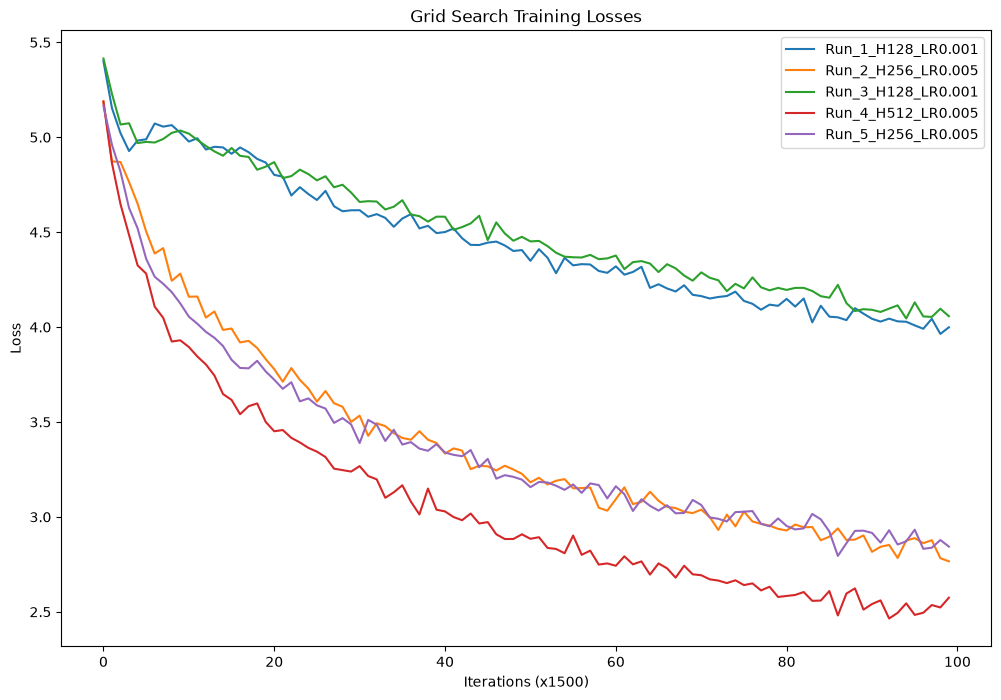


Search Complete. Best parameters: {'hidden_size': 512, 'lr': 0.005} with loss 2.5225


In [7]:
# Kick off 5 random configurations, training for 1.5 epochs each
run_random_search(n_runs=5, n_iters=150000, print_every=15000, plot_every=1500)

In [12]:
import sys
import os
sys.path.append(os.path.abspath('..'))

import torch
import torch.nn as nn
import torch.nn.functional as F
from src.translation_utils import *
import random
input_lang, output_lang, pairs = prepareData('eng', 'fra', reverse=False)

def evaluate(encoder, decoder, sentence, max_length=MAX_LENGTH):
    with torch.no_grad():
        # Convert input string to tensor
        input_tensor = tensorFromSentence(input_lang, sentence)
        input_length = input_tensor.size(0)
        
        # 1. Initialize tensor to store encoder outputs for Attention
        encoder_outputs = torch.zeros(max_length, encoder.hidden_size, device=device)
        
        # Pass through Encoder
        encoder_hidden = encoder.init_hidden()
        for ei in range(input_length):
            encoder_output, encoder_hidden = encoder(input_tensor[ei].unsqueeze(0), encoder_hidden)
            # 2. Store the output for the attention mechanism
            encoder_outputs[ei] = encoder_output[0, 0]
            
        # Prepare Decoder
        decoder_input = torch.tensor([[SOS_token]], device=device)
        decoder_hidden = encoder_hidden
        decoded_words = []
        
        # Decode word-by-word
        for di in range(max_length):
            # 3. Pass encoder_outputs and unpack decoder_attention
            decoder_output, decoder_hidden, decoder_attention = decoder(
                decoder_input, decoder_hidden, encoder_outputs)
            
            topv, topi = decoder_output.topk(1)
            
            # Check for End of Sentence
            if topi.item() == EOS_token:
                decoded_words.append('<EOS>')
                break
            else:
                decoded_words.append(output_lang.index2word[topi.item()])
                
            # Set current prediction as next input
            decoder_input = topi.view(1, 1).detach()
            
        return ' '.join(decoded_words)

Reading lines...
Read 135842 sentence pairs
Trimmed to 135083 sentence pairs
Counting words...
Counted words:
eng 12890
fra 21143


In [13]:
def test_best_model(sentence, best_hidden_size):
    # Initialize models with the winning hidden size
    encoder = EncoderRNN(input_lang.n_words, best_hidden_size).to(device)
    decoder = AttnDecoderRNN(best_hidden_size, output_lang.n_words).to(device)
    
    # Load the saved weights
    encoder.load_state_dict(torch.load('../modelV2/best_encoder.pth', weights_only=True))
    decoder.load_state_dict(torch.load('../modelV2/best_decoder.pth', weights_only=True))
    
    # Set to evaluation mode
    encoder.eval()
    decoder.eval()
    
    # Run translation
    output_sentence = evaluate(encoder, decoder, sentence)
    print(f"Input:  {sentence}")
    print(f"French: {output_sentence}")

In [14]:
test_best_model('just get back to work .', best_hidden_size=512)

Input:  just get back to work .
French: restez simplement au travail . <EOS>


In [18]:
test_best_model('is this made in switzerland ?', best_hidden_size=512)

Input:  is this made in switzerland ?
French: est ce que dans la ? ? <EOS>


In [21]:
test_best_model('hello how are you ?', best_hidden_size=512)

Input:  hello how are you ?
French: oh tu ? ? <EOS>


In [22]:
test_best_model('i am cold .', best_hidden_size=512)

Input:  i am cold .
French: je suis froid . <EOS>


In [23]:
test_best_model('are you sure ?', best_hidden_size=512)

Input:  are you sure ?
French: etes tu sur d <EOS>


In [24]:
test_best_model('i love you', best_hidden_size=512)

Input:  i love you
French: j adore t aime . <EOS>
